# 3. modell – Embedding + Conv1D + GlobalMaxPooling1D + Dense (CNN)

**Architektúra:** `Embedding → Conv1D(128, kernel_size=5, relu) → GlobalMaxPooling1D → Dropout → Dense(1, sigmoid)`

Az adat-előkészítés, a felosztás, a tokenizer és a kiértékelés a közös `dl_prep.py`-ból jön, ugyanúgy, mint a többi DL modellnél:
- cikkenkénti GroupShuffleSplit (random_state=42), a test **csak a legvégén** kerül elő,
- a train-ből 12% (cikkenként) a validációs halmaz, erre figyel az EarlyStopping,
- egy tokenizer, csak a train szövegeken illesztve, `num_words=20 000`, `maxlen` = 95. percentilis.

**Kísérletek** (mindegyik a *validációs* halmazon, 3 seed – 42, 43, 44 – átlaga):
1. `kernel_size` 3 / 5 / 7: hogyan változik a modell teljesítménye az eltérő hosszúságú szómintázatok vizsgálatakor.
2. Szűrőszám: 64 / 128 / 256, valamint egy második Conv1D réteg hatása.
3. Tanulási görbe Dropout nélkül és Dropouttal, EarlyStopping nélkül 30 epochon: így megfigyelhető a túltanulás.

**Bónusz:** a Conv1D szűrők legerősebb aktivációihoz tartozó n-gramok vizsgálata.


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tensorflow import keras
from tensorflow.keras import layers
import dl_prep as dp

SEEDS = [42, 43, 44]
dp.set_seeds(42)
data = dp.load_data()
print(data.summary())

train: 10370 mondat (527 cikk) | val: 1446 (72 cikk) | test: 3048 (150 cikk)
szókincs (train): 11893 szó, ebből használt: 11894 index | maxlen: 48 token


## Modellépítés

A `Conv1D` egymás melletti tokenek embeddingjein alkalmaz szűrőket: `kernel_size=5` öt szomszédos tokenre lát rá. A `GlobalMaxPooling1D` szűrőnként a legerősebb aktivációt választja ki. A végső sigmoid érték 0 és 1 közötti szakmai-valószínűség.

**Padding:** ennél a CNN-nél `mask_zero=False`, mert a Conv1D nem kezeli automatikusan a Keras Embedding maszkját. A paddinggel érintkező ablakok hatása az eredmény értelmezésekor figyelembe veendő.

In [13]:
def build_model(kernel_size=5, filters=128, second_conv=False, dropout=0.3):
    """Konfigurálható szövegosztályozó CNN; minden kísérlet ugyanazt a dp adatot használja."""
    model = keras.Sequential(name="medplain_cnn")
    model.add(keras.Input(shape=(data.maxlen,)))
    model.add(layers.Embedding(data.vocab_size, dp.EMBED_DIM, mask_zero=False, name="embedding"))
    model.add(layers.Conv1D(filters, kernel_size=kernel_size, activation="relu", padding="valid", name="conv1"))
    if second_conv:
        model.add(layers.Conv1D(filters, kernel_size=3, activation="relu", padding="valid", name="conv2"))
    model.add(layers.GlobalMaxPooling1D(name="global_max_pool"))
    if dropout > 0:
        model.add(layers.Dropout(dropout, name="dropout"))
    model.add(layers.Dense(1, activation="sigmoid", name="prediction"))
    return dp.compile_model(model)

assert data.maxlen >= 9, "A két egymást követő valid Conv1D réteghez legalább 9 token szükséges."
dp.set_seeds(42)
build_model().summary()

Model: "medplain_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 48, 100)             │       1,189,400 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1 (Conv1D)                       │ (None, 44, 128)             │          64,128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_max_pool (GlobalMaxPooling1D) │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ prediction (Dense)                   │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,253,657 (4.78 MB)

 Trainable params: 1,253,657 (4.78 MB)

 Non-trainable params: 0 (0.00 B)

## 1. Kísérletek: kernelméret, szűrők, második réteg és Dropout

Az alábbi paraméterkombinációknál minden modell 3 eltérő seeddel tanul. **Nem érintjük a tesztadatokat.** Az eredmények a validációs accuracy és F1 átlagát, szórását, valamint a legjobb val_loss értékét tartalmazzák. A sorrendet az átlagos validációs F1 határozza meg, döntetlennél accuracy.

In [14]:
CONFIGS = [
    ("kernel=3",        dict(kernel_size=3, filters=128, second_conv=False, dropout=0.3)),
    ("kernel=5",        dict(kernel_size=5, filters=128, second_conv=False, dropout=0.3)),
    ("kernel=7",        dict(kernel_size=7, filters=128, second_conv=False, dropout=0.3)),
    ("filters=64",      dict(kernel_size=5, filters=64,  second_conv=False, dropout=0.3)),
    ("filters=256",     dict(kernel_size=5, filters=256, second_conv=False, dropout=0.3)),
    ("2x Conv1D",       dict(kernel_size=5, filters=128, second_conv=True,  dropout=0.3)),
    ("Dropout nélkül",  dict(kernel_size=5, filters=128, second_conv=False, dropout=0.0)),
]

def run_config(label, params):
    records = []
    for seed in SEEDS:
        keras.backend.clear_session()
        dp.set_seeds(seed)
        model = build_model(**params)
        history, seconds = dp.fit(model, data)
        score = dp.evaluate(model, data, split="val")
        records.append({"seed": seed, "val_accuracy": score["accuracy"],
                        "val_f1": score["f1"], "val_loss_best": min(history.history["val_loss"]),
                        "best_epoch": dp.best_epoch(history), "train_seconds": seconds})
        print(f"  {label:19} seed={seed}: F1={score['f1']:.4f}, acc={score['accuracy']:.4f}")
    frame = pd.DataFrame(records)
    return {"beállítás": label,
            "val_f1": frame.val_f1.mean(), "f1_std": frame.val_f1.std(),
            "val_accuracy": frame.val_accuracy.mean(), "accuracy_std": frame.val_accuracy.std(),
            "val_loss_best": frame.val_loss_best.mean(),
            "best_epoch": frame.best_epoch.mean(),
            "train_seconds": frame.train_seconds.mean()}

experiment_rows = []
for label, params in CONFIGS:
    print("Kísérlet:", label)
    experiment_rows.append(run_config(label, params))
comparison = pd.DataFrame(experiment_rows).sort_values(
    ["val_f1", "val_accuracy"], ascending=False).reset_index(drop=True)
display(comparison.round(4))

Kísérlet: kernel=3
  kernel=3            seed=42: F1=0.7924, acc=0.7822
  kernel=3            seed=43: F1=0.7698, acc=0.7787
  kernel=3            seed=44: F1=0.7138, acc=0.7427
Kísérlet: kernel=5
  kernel=5            seed=42: F1=0.7975, acc=0.7953
  kernel=5            seed=43: F1=0.7764, acc=0.7828
  kernel=5            seed=44: F1=0.7539, acc=0.7683
Kísérlet: kernel=7
  kernel=7            seed=42: F1=0.8011, acc=0.7918
  kernel=7            seed=43: F1=0.7959, acc=0.8057
  kernel=7            seed=44: F1=0.7854, acc=0.7884
Kísérlet: filters=64
  filters=64          seed=42: F1=0.7711, acc=0.7676
  filters=64          seed=43: F1=0.7517, acc=0.7739
  filters=64          seed=44: F1=0.7367, acc=0.7573
Kísérlet: filters=256
  filters=256         seed=42: F1=0.7712, acc=0.7801
  filters=256         seed=43: F1=0.7690, acc=0.7794
  filters=256         seed=44: F1=0.7469, acc=0.7614
Kísérlet: 2x Conv1D
  2x Conv1D           seed=42: F1=0.7400, acc=0.7614
  2x Conv1D           seed=43: F

,beállítás,val_f1,f1_std,val_accuracy,accuracy_std,val_loss_best,best_epoch,train_seconds
0,kernel=7,0.7941,0.0080,0.7953,0.0091,0.4393,1.3333,7.9611
1,Dropout nélkül,0.7926,0.0081,0.7932,0.0100,0.4416,1.0000,6.1549
2,kernel=5,0.7759,0.0218,0.7822,0.0135,0.4548,1.3333,6.2398
3,filters=256,0.7624,0.0135,0.7736,0.0106,0.4630,1.0000,7.3501
4,2x Conv1D,0.7619,0.0457,0.7699,0.0230,0.4737,1.0000,7.4904
5,kernel=3,0.7587,0.0404,0.7679,0.0218,0.4905,1.0000,5.3991
6,filters=64,0.7532,0.0173,0.7663,0.0084,0.4897,1.3333,6.3923


## 2. Választás kizárólag validáció alapján

A nyertes konfigurációt az átlagos validációs F1 (döntetlen esetén accuracy) szerint választjuk. A végső modellel újra tanulunk fix seed=42-vel. A tesztadatokhoz eddig nem nyúltunk.

In [15]:
best_name = comparison.iloc[0]["beállítás"]
best_params = dict(next(params for label, params in CONFIGS if label == best_name))
print("Választott konfiguráció:", best_name, best_params)
print("Átlagos validációs F1:", round(float(comparison.iloc[0]["val_f1"]), 4))

Választott konfiguráció: kernel=7 {'kernel_size': 7, 'filters': 128, 'second_conv': False, 'dropout': 0.3}
Átlagos validációs F1: 0.7941


## 3. Tanulási görbék Dropout nélkül és Dropouttal

A nyertes CNN rétegbeállításaival összevetjük a két Dropout-értéket. A görbékhez 30 teljes epochot futtatunk EarlyStopping nélkül, hogy a túltanulás látható legyen; ezek **nem** a végső modell súlyai.

Dropout nélkül legjobb epoch: 1 legjobb val_loss: 0.4416
Dropouttal (0.3) legjobb epoch: 1 legjobb val_loss: 0.4387


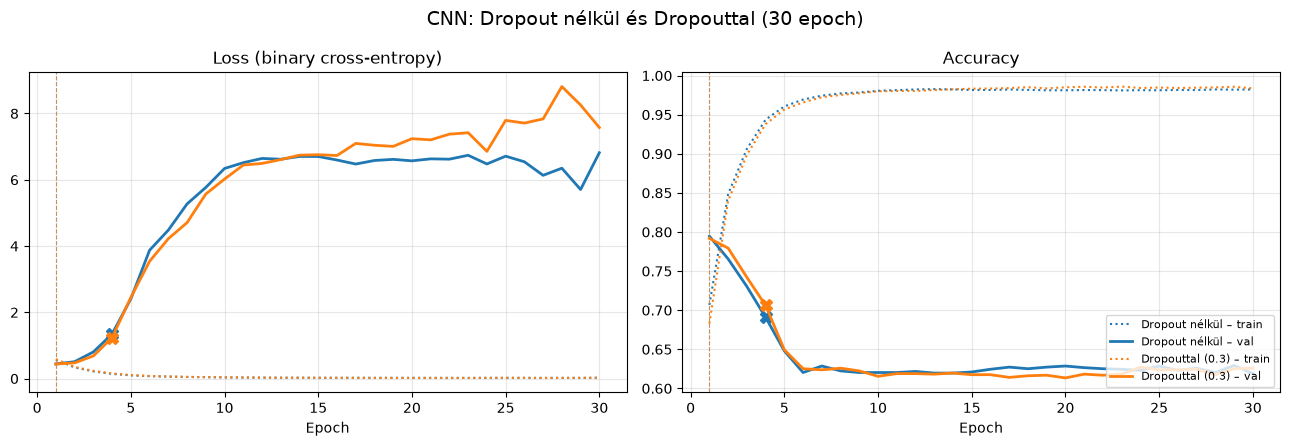

In [16]:
curves = {}
for label, drop in [("Dropout nélkül", 0.0), ("Dropouttal (0.3)", 0.3)]:
    keras.backend.clear_session()
    dp.set_seeds(42)
    m = build_model(**{**best_params, "dropout": drop})
    history, secs = dp.fit(m, data, epochs=30, use_early_stopping=False)
    curves[label] = history
    print(label, "legjobb epoch:", dp.best_epoch(history),
          "legjobb val_loss:", round(min(history.history["val_loss"]), 4))
dp.plot_history(curves, "CNN: Dropout nélkül és Dropouttal (30 epoch)")
plt.show()

## 4. Végső modell és egyszeri teszt

Új példányt tanítunk a kiválasztott hiperparaméterekkel, a közös `dp.fit()` EarlyStoppingját használva. Az alábbi **egyetlen** `split="test"` hívás adja a végső mérőszámokat.

Model: "medplain_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 48, 100)             │       1,189,400 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1 (Conv1D)                       │ (None, 42, 128)             │          89,728 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_max_pool (GlobalMaxPooling1D) │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ prediction (Dense)                   │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,279,257 (4.88 MB)

 Trainable params: 1,279,257 (4.88 MB)

 Non-trainable params: 0 (0.00 B)

Teszt accuracy: 0.7831
Teszt F1-score: 0.7940
Tanítás: 6.6 s, best epoch: 1


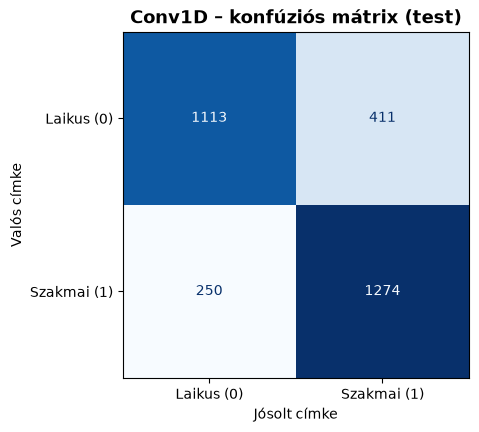

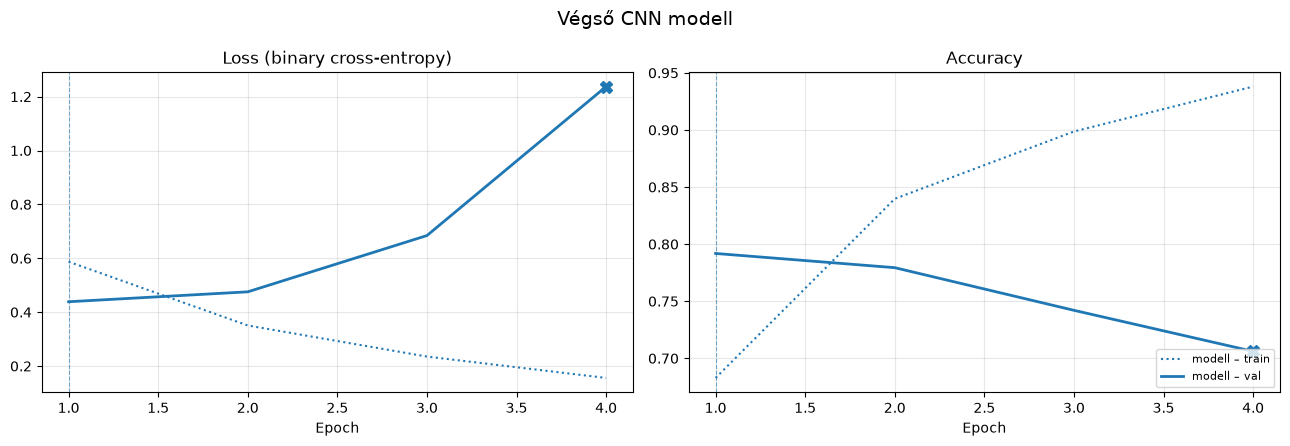

In [17]:
keras.backend.clear_session()
dp.set_seeds(42)
final_model = build_model(**best_params)
final_model.summary()
final_history, final_seconds = dp.fit(final_model, data)

# Egyetlen tesztkiértékelés – csak a validáció alapján véglegesített modellen.
test_result = dp.evaluate(final_model, data, split="test")
print(f"Teszt accuracy: {test_result['accuracy']:.4f}")
print(f"Teszt F1-score: {test_result['f1']:.4f}")
print(f"Tanítás: {final_seconds:.1f} s, best epoch: {dp.best_epoch(final_history)}")

dp.plot_confusion(test_result["confusion_matrix"], "Conv1D – konfúziós mátrix (test)")
plt.show()
dp.plot_history(final_history, "Végső CNN modell")
plt.show()

## 5. Bónusz: mire aktiválódnak a Conv1D szűrők?

A `conv1` réteg előtti embeddinget és a konvolúció kimenetét vizsgáljuk a **validációs** mondatokon. Minden szűrőhöz megkeressük a legerősebb validációs aktivációt és a hozzá tartozó `kernel_size` hosszú tokensorozatot. Ezek a Keras tokenizer szerinti tokenek, nem feltétlenül tökéletesen rekonstruált eredeti kifejezések. Paddinget tartalmazó ablakokat kihagyunk. Kétrétegű CNN-nél is az első konvolúció szűrőit elemezzük.

In [18]:
conv_layer = final_model.get_layer("conv1")
activation_model = keras.Model(inputs=final_model.inputs,
                               outputs=conv_layer.output)
# A validációs halmaz rövid; batchenként vizsgáljuk, hogy a memóriaigény alacsony maradjon.
k = best_params["kernel_size"]
num_filters = best_params["filters"]
best_activation = np.full(num_filters, -np.inf)
best_sample = np.full(num_filters, -1, dtype=int)
best_position = np.full(num_filters, -1, dtype=int)
for start in range(0, len(data.x_val), 64):
    batch = data.x_val[start:start+64]
    acts = activation_model.predict(batch, verbose=0)
    for row in range(len(batch)):
        # Csak valódi tokeneket tartalmazó Conv1D-ablakokat vizsgálunk.
        real_len = int(np.count_nonzero(batch[row]))
        valid_positions = real_len - k + 1
        if valid_positions <= 0:
            continue
        valid_acts = acts[row, :valid_positions, :]
        positions = valid_acts.argmax(axis=0)
        values = valid_acts[positions, np.arange(num_filters)]
        better = values > best_activation
        best_activation[better] = values[better]
        best_sample[better] = start + row
        best_position[better] = positions[better]

index_word = data.tokenizer.index_word
examples = []
for f in np.argsort(best_activation)[::-1]:
    if best_sample[f] < 0:
        continue
    seq = data.x_val[best_sample[f], best_position[f]:best_position[f]+k]
    words = " ".join(index_word.get(int(token), "<OOV>") for token in seq)
    examples.append({"szűrő": int(f), "max_aktiváció": float(best_activation[f]),
                     "tokenablak": words, "val_mondat": data.val_df.iloc[best_sample[f]]["text"]})
filter_examples = pd.DataFrame(examples)
display(filter_examples.head(15))

,szűrő,max_aktiváció,tokenablak,val_mondat
0,31,1.010340,researchers also studied how well treatments w...,Researchers also studied how well treatments w...
1,17,0.959456,if cells don't get enough blood sugar,The best measures at this time are the results...
2,56,0.956129,p 0 001 walking p 0 001,"In addition, there was a significant improveme..."
3,18,0.953211,p 0 001 walking p 0 001,"In addition, there was a significant improveme..."
4,14,0.920599,cells don't get enough blood sugar food,The best measures at this time are the results...
5,94,0.907345,p 0 001 walking p 0 001,"In addition, there was a significant improveme..."
6,2,0.885108,researchers also studied how well treatments w...,Researchers also studied how well treatments w...
7,96,0.882995,if cells don't get enough blood sugar,The best measures at this time are the results...
8,25,0.864956,health condition that affects how the body,Current controversies and arguments for nutrit...
9,54,0.864601,p 0 001 at rest p 0,The pain scores before surgery were significan...


## 6. Eredmények mentése

A közös összehasonlító notebook a `results/cnn.json` állományt olvassa. **Csak a végső teszteredményt** mentjük, nem a validációs kísérletek becsléseit.

In [19]:
output_path = dp.save_result(
    key="cnn", name="Embedding + Conv1D + GlobalMaxPooling1D",
    model=final_model, history=final_history, result=test_result,
    train_seconds=final_seconds, data=data,
    params={**best_params, "seeds_for_validation": SEEDS,
            "validation_selection": "mean F1, tie-break mean accuracy"},
    notes=f"Validáció alapján kiválasztott modell: {best_name}; "
          f"val F1 átlag: {comparison.iloc[0]['val_f1']:.4f}; "
          f"val acc átlag: {comparison.iloc[0]['val_accuracy']:.4f}",
)
print("Mentve:", output_path)

# Kiegészítő kísérlettábla csak lokálisan; nem szükséges commitolni.
# comparison.to_csv("cnn_validation_experiments.csv", index=False)

Mentve: C:\Projektmunka I\Projektmunka_I\results\cnn.json


## 7. Rövid összefoglaló / diához

A következő cella a **valóban lefutott eredményekből** generál rövid magyar beszámolót. A számokat csak futtatás után használd a prezentációban.

In [20]:
print(f"""MedPlain – Barni / CNN
Feladat: szakmai (1) és laikus (0) angol orvosi mondatok bináris osztályozása.
A modell Embedding → Conv1D → (opcionális Conv1D) → GlobalMaxPooling1D →
(opcionális Dropout) → sigmoid kimenet rétegekből áll.
Kipróbáltunk 3, 5 és 7 tokenes kernelméretet, 64/128/256 szűrőt,
egy második Conv1D réteget és Dropoutot.
Választás a validációs 3 seed alapján: {best_name}, {best_params}.
Átlagos validációs F1: {comparison.iloc[0]['val_f1']:.4f},
átlagos validációs accuracy: {comparison.iloc[0]['val_accuracy']:.4f}.
Egyszeri teszt: accuracy={test_result['accuracy']:.4f}, F1={test_result['f1']:.4f}.
Paraméterszám: {final_model.count_params():,}; tanítási idő: {final_seconds:.1f} s.
A legjobban aktiválódó tokenablakok az előző táblázatban láthatók.
""")

MedPlain – Barni / CNN
Feladat: szakmai (1) és laikus (0) angol orvosi mondatok bináris osztályozása.
A modell Embedding → Conv1D → (opcionális Conv1D) → GlobalMaxPooling1D →
(opcionális Dropout) → sigmoid kimenet rétegekből áll.
Kipróbáltunk 3, 5 és 7 tokenes kernelméretet, 64/128/256 szűrőt,
egy második Conv1D réteget és Dropoutot.
Választás a validációs 3 seed alapján: kernel=7, {'kernel_size': 7, 'filters': 128, 'second_conv': False, 'dropout': 0.3}.
Átlagos validációs F1: 0.7941,
átlagos validációs accuracy: 0.7953.
Egyszeri teszt: accuracy=0.7831, F1=0.7940.
Paraméterszám: 1,279,257; tanítási idő: 6.6 s.
A legjobban aktiválódó tokenablakok az előző táblázatban láthatók.

